# Tutorial 3: Variable coefficients, accuracy and cost

We solve an anisotropic, heterogeneous diffusion–reaction problem on $[-1,1]^2$,

$$
-\nabla\cdot\big(a(x,y)\,K\,\nabla u\big) + u = f, \qquad
K=\begin{pmatrix}1 & 0.6\\ 0.6 & 1\end{pmatrix},
$$

with $a(x,y)=1+0.5\sin(\pi x)\cos(\pi y)$, a localized source $f$, $u=0$ on $x=\pm1$ and zero flux on
$y=\pm1$. This tutorial shows how to set a full, variable principal tensor, how to check the QTT
solver against the dense one, how to control accuracy and inspect bond dimensions, and what
determines the cost.

In [1]:
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
from seemps.analysis.cross import BlackBoxLoadMPS, CrossStrategyDMRG, cross_interpolation
from seemps.analysis.mesh import ChebyshevInterval, Mesh, mps_to_mesh_matrix
from seemps.state import MPS, Strategy, Truncation, Simplification

from seemps_galerkin import (
    BoundaryFace,
    BoundaryProblem,
    BulkProblem,
    DirichletBoundaryCondition,
    RobinBoundaryCondition,
    TensorField,
)
from seemps_galerkin.dense.factories import vec_nd_chebyshev_transform
from seemps_galerkin.logger import Logger
from seemps_galerkin.mps.factories import mps_identity, mps_zeros
from seemps_galerkin.mps.factories.transform import mps_chebyshev_transform
from seemps_galerkin.mps.linear import AMEnSolver
from seemps_galerkin.solve import solve_dense_bvp, solve_mps_bvp

K = np.array([[1.0, 0.6], [0.6, 1.0]])


def a(x, y):
    return 1 + 0.5 * np.sin(np.pi * x) * np.cos(np.pi * y)


def f(x, y):
    return np.exp(-20 * ((x - 0.3) ** 2 + (y + 0.2) ** 2))


def tci(func, mesh):
    sites = [int(np.log2(N)) for N in mesh.dimensions]
    black_box = BlackBoxLoadMPS(
        lambda points: func(*points),
        mesh,
        map_matrix=mps_to_mesh_matrix(sites),
        physical_dimensions=[2] * sum(sites),
    )
    return cross_interpolation(black_box, CrossStrategyDMRG(tol=1e-12)).mps

## 1. The problem

The principal tensor has entries `principal[α, β, μ, ν]` for $C_{\mu\alpha\nu\beta}$. Here
$C_{\alpha\beta}=a(x,y)\,K_{\alpha\beta}$, so all four entries are set, each a scaled copy of the
same QTT. Zero-flux faces are Robin conditions with empty fields, and $u=0$ is a Dirichlet condition
with zero data (`mps_zeros`).

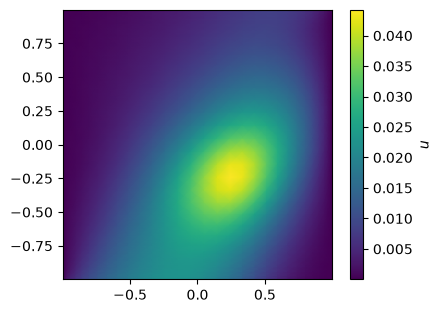

In [2]:
def build_problem(n):
    N = 2**n
    interval = ChebyshevInterval(-1.0, 1.0, N, endpoints=False)
    mesh = Mesh([interval, interval])
    ψ_a = tci(a, mesh)
    principal = TensorField[MPS]((2, 2, 1, 1), mesh.dimensions)
    for α in range(2):
        for β in range(2):
            principal[α, β, 0, 0] = K[α, β] * ψ_a
    reaction = TensorField[MPS]((1, 1), mesh.dimensions)
    reaction[0, 0] = mps_identity(2 * n)
    source = TensorField[MPS]((1,), mesh.dimensions)
    source[0] = tci(f, mesh)
    bulk = BulkProblem(mesh, principal, reaction, source)

    face = (N,)
    conditions = []
    for is_left in (True, False):
        data = TensorField[MPS]((1,), face)
        data[0] = mps_zeros(n)
        conditions.append(DirichletBoundaryCondition(BoundaryFace(0, is_left), data))
        conditions.append(
            RobinBoundaryCondition(
                BoundaryFace(1, is_left), TensorField[MPS]((1, 1), face), TensorField[MPS]((1,), face)
            )
        )
    return bulk, BoundaryProblem(mesh, conditions)


n = 5
bulk, boundary = build_problem(n)
ψ = solve_mps_bvp(bulk, boundary)
u = mps_chebyshev_transform(ψ, [n, n], inverse=True).to_vector().reshape(2**n, 2**n)

x = bulk.mesh.intervals[0].to_vector()
X, Y = np.meshgrid(x, x, indexing="ij")
fig, ax = plt.subplots(figsize=(4.5, 3.5))
image = ax.pcolormesh(X, Y, u, shading="gouraud")
fig.colorbar(image, ax=ax, label="$u$")
ax.set_aspect("equal")
plt.show()

## 2. Checking against the dense solver

Every QTT problem has a dense counterpart with the same discretization. Expanding the MPS fields
into NumPy vectors (here with `to_vector`) and calling `solve_dense_bvp` gives a reference for
moderate sizes. The two agree up to the tolerance of the QTT solver.

In [3]:
def to_dense(field):
    out = TensorField[np.ndarray](field.field_shape, field.mesh_shape)
    for index in np.ndindex(field.field_shape):
        if field[index] is not None:
            out[index] = field[index].to_vector()
    return out


bulk_dense = BulkProblem(bulk.mesh, to_dense(bulk.principal), to_dense(bulk.reaction), to_dense(bulk.source))
boundary_dense = BoundaryProblem(
    bulk.mesh,
    [
        DirichletBoundaryCondition(bc.face, to_dense(bc.data))
        if isinstance(bc, DirichletBoundaryCondition)
        else RobinBoundaryCondition(bc.face, to_dense(bc.reaction), to_dense(bc.data))
        for bc in boundary.boundary_conditions
    ],
)
u_dense = vec_nd_chebyshev_transform(solve_dense_bvp(bulk_dense, boundary_dense), (2**n, 2**n), inverse=True)
print(f"QTT vs dense: {np.max(np.abs(u.ravel() - u_dense)) / np.max(np.abs(u_dense)):.1e}")

QTT vs dense: 2.5e-08


## 3. Accuracy and solver settings

Two settings control accuracy:

- the **truncation strategy** (`strategy=`), a SeeMPS `Strategy` whose tolerance bounds the
  singular values discarded at each compression;
- the **linear solver** (`solver=`), by default `AMEnSolver` with Jacobi preconditioning, whose
  `rtol` sets the target residual.

The `Logger` records the bond dimensions of the operator, the right-hand side and the solution.

In [4]:
for tol in (1e-6, 1e-8, 1e-10):
    strategy = Strategy(
        method=Truncation.RELATIVE_SINGULAR_VALUE,
        tolerance=tol,
        simplification_tolerance=tol,
        simplify=Simplification.VARIATIONAL,
    )
    Logger.activate(level=0, collect=True)
    ψ_tol = solve_mps_bvp(bulk, boundary, strategy=strategy, solver=AMEnSolver(rtol=tol, strategy=strategy))
    χ_A = max(Logger.sink["solve.mps.A_dirichlet.bond_dimensions"][-1])
    Logger.deactivate()
    Logger.clear()
    u_tol = mps_chebyshev_transform(ψ_tol, [n, n], inverse=True).to_vector()
    error = np.max(np.abs(u_tol - u_dense)) / np.max(np.abs(u_dense))
    print(f"tolerance {tol:.0e}: error vs dense {error:.1e}, χ(A) = {χ_A}, χ(u) = {ψ_tol.max_bond_dimension()}")

/home/juanjo/Workspace/Projects/Galerkin/Remote/src/seemps_galerkin/mps/linear.py:102: RuntimeWarning: AMEn did not converge: relative residual 3.943e-05 > 1.000e-06
  ψ = amen_solve(


tolerance 1e-06: error vs dense 7.9e-05, χ(A) = 54, χ(u) = 24


tolerance 1e-08: error vs dense 2.3e-07, χ(A) = 63, χ(u) = 30


tolerance 1e-10: error vs dense 2.5e-08, χ(A) = 64, χ(u) = 30


Two effects appear here. At the loosest tolerance, AMEn warns that it did not reach the requested
residual, because the truncation itself limits the attainable residual. And the error stops
improving at about $10^{-8}$: the spectral operator is ill-conditioned, so truncation errors are
amplified (see the preconditioning appendix of the paper).

## 4. Resolution and cost

To check convergence without expanding the solution, we evaluate $u$ at the center of the domain
from its Chebyshev coefficients, $u(0,0)=\sum_{jk} c_{jk}T_j(0)T_k(0)$. The weights $T_j(0)$ are
built as a QTT with the site layout of the coefficients, which store the index of each coordinate
least significant bit first, and contracted with the solution site by site.

The cost of the QTT solver is governed by the bond dimensions and by the number of AMEn sweeps,
which grows with $N$ because the spectral operator becomes ill-conditioned. The method pays off
when high resolutions or many coordinates are needed while the bond dimensions stay small, as in
the three-dimensional and parametric experiments of the paper; for this smooth 2D problem,
$N=64$ is already converged to about $10^{-8}$.

In [5]:
def value_at_origin(ψ, n):
    reversal = np.array([int(f"{i:0{n}b}"[::-1], 2) for i in range(2**n)])
    weights = MPS.from_vector(np.cos(np.arange(2**n) * np.pi / 2)[reversal], [2] * n, normalize=False)
    environment = np.ones((1, 1))
    for core, w in zip(ψ, list(weights) * 2):
        environment = np.einsum("ab,aic,bid->cd", environment, core, w)
    return float(environment[0, 0])


for n in (4, 5, 6):
    bulk, boundary = build_problem(n)
    tick = perf_counter()
    Logger.activate(level=0, collect=True)
    ψ = solve_mps_bvp(bulk, boundary, solver=AMEnSolver(rtol=1e-8))
    χ_A = max(Logger.sink["solve.mps.A_dirichlet.bond_dimensions"][-1])
    Logger.deactivate()
    Logger.clear()
    print(
        f"N = {2**n:3d}: {perf_counter() - tick:4.1f} s, χ(A) = {χ_A}, χ(u) = {ψ.max_bond_dimension()}, "
        f"u(0, 0) = {value_at_origin(ψ, n):.10f}"
    )

N =  16:  0.3 s, χ(A) = 29, χ(u) = 14, u(0, 0) = 0.0247626224


N =  32:  0.8 s, χ(A) = 64, χ(u) = 30, u(0, 0) = 0.0247438341


N =  64:  5.4 s, χ(A) = 91, χ(u) = 53, u(0, 0) = 0.0247441098


## Summary

- `principal[α, β, μ, ν]` holds $C_{\mu\alpha\nu\beta}$; any entry can be a variable field, and
  anisotropic or non-separable coefficients are as easy as isotropic ones.
- The dense solver is a reference for checking QTT setups at moderate sizes.
- `strategy` and `solver` control accuracy and cost; the `Logger` reports the bond dimensions.
- Quantities of interest can be evaluated directly from the compressed coefficients.